In [ ]:
import warnings
warnings.filterwarnings("ignore")
from ddgs import DDGS
from fastbook import * 

In [10]:
def search_images_ddg(term, max_images = 200):
    results = DDGS().images(term, max_results=max_images)
    return L(r['image'] for r in results)

In [11]:
urls = search_images_ddg('bird photos', max_images=1)
len(urls), urls[0]

(1,
 'https://images.pexels.com/photos/326900/pexels-photo-326900.jpeg?cs=srgb&dl=wood-flight-bird-326900.jpg&fm=jpg')

In [12]:
dest = Path("bird.jpg")
if not dest.exists(): download_url(urls[0], dest, show_progress=False)

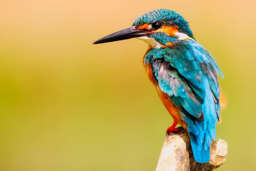

In [13]:
im = Image.open(dest)
im.to_thumb(256,256)

In [14]:
import time
searches = 'forest', 'bird'
path = Path('bird_or_not')

for o in searches:
    dest = path/o
    dest.mkdir(exist_ok=True, parents=True)
    for variant in ['sun', 'shade', 'autumn', 'winter']:
        results = search_images_ddg(f'{o} {variant} photo')
        download_images(dest, urls=results)
        time.sleep(3)
    resize_images(dest, max_size=400, dest=dest)

failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(get_image_files(path))

/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-pa

262

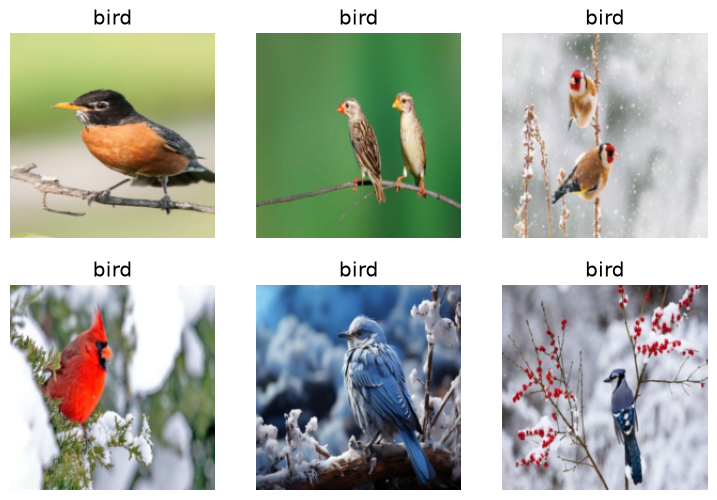

In [15]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path)

dls.show_batch(max_n=6)

In [16]:
learn = cnn_learner(dls, resnet18, metrics = error_rate)
learn.fine_tune(3)

/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/fastai/vision/learner.py:304: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,error_rate,time
0,1.122616,0.868816,0.307692,00:21


/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-pa

epoch,train_loss,valid_loss,error_rate,time
0,0.231688,0.110562,0.057692,00:23
1,0.136304,0.151636,0.057692,00:25
2,0.090181,0.176248,0.057692,00:28


/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-pa

In [23]:
is_bird,_,probs = learn.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability of it being a bird: {probs[0]}")

<div><progress max="1" value="0"></progress> 0.00% [0/1 00:00&lt;?]</div>

This is a: bird.
Probability of it being a bird: 0.9998577833175659


/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-pa

/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/ani/Codes/Birdie/vnev/lib64/python3.14/site-pa

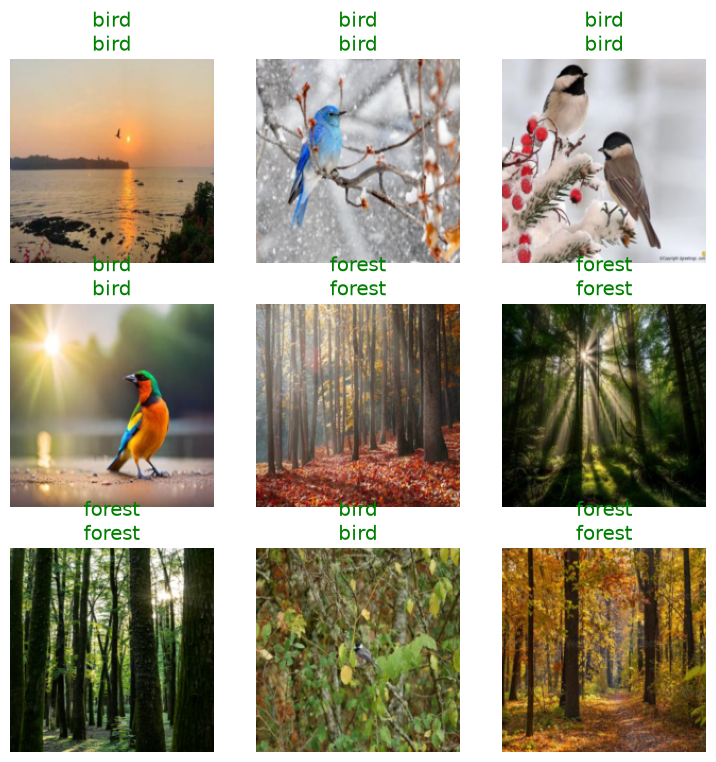

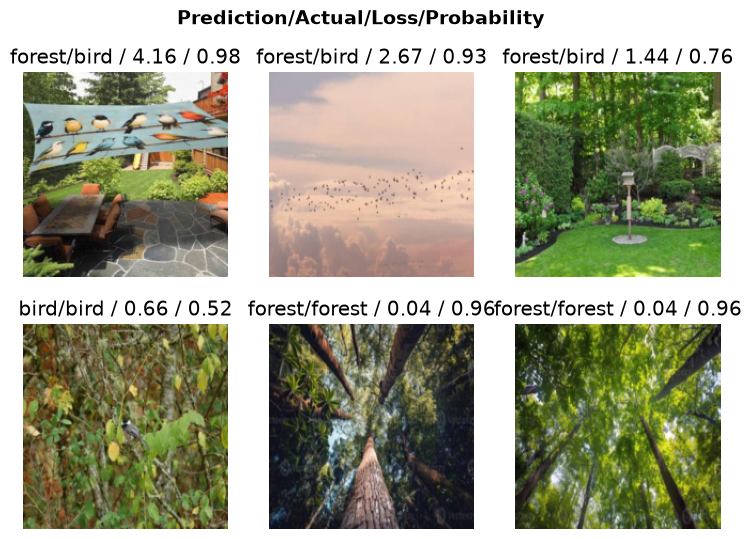

In [22]:
learn.dls.vocab
learn.show_results()
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_top_losses(6, nrows=2)